# Notebook 3 -- OTFS End-to-End Pipeline as Sionna-Compatible Precoded OFDM

This notebook implements OTFS modulation as **precoded OFDM** and demonstrates a complete end-to-end link: from information bits placed in the delay-Doppler domain, through the OFDM waveform and a doubly dispersive channel, back to the delay-Doppler domain at the receiver.

The implementation is Sionna-compatible by design. The OTFS modulator and demodulator wrap Sionna's standard OFDM chain without modifying it -- the ISFFT precoding step inserts between the `ResourceGridMapper` and the `OFDMModulator`; the SFFT deprecoding step inserts between the `OFDMDemodulator` and the `ResourceGridDemapper`.

```
  DD grid        OTFS           TF grid        OFDM         Time-domain
  X[l, k]  -->  Modulator  --> X_tf[m,n]  -->  Modulator -->   waveform
              (ISFFT)                       (IFFT + CP)

  DD grid        OTFS           TF grid        OFDM         Time-domain
  Y[l, k]  <--  Demodulator <-- Y_tf[m,n]  <-- Demodulator <-- waveform
              (SFFT)                        (CP removal + FFT)
```

Channel estimation is not performed here. The embedded pilot and guard region are included so that the frame structure matches the estimation experiments in Notebook 4. Perfect-CSI block LMMSE equalization is included as a performance reference.

**Plotting convention used throughout:**
- Delay-Doppler grids: Doppler on the x-axis, delay on the y-axis.
- Time-frequency grids: OFDM symbol index on the x-axis, subcarrier index on the y-axis.
- Complex heatmaps: magnitude first, then phase immediately after.
- Phase is masked wherever the magnitude is below a relative threshold.

**The notebook covers:**
- `OTFSModulator` and `OTFSDemodulator` from `otfs_sim.phy.otfs` (ISFFT / SFFT precoding and deprecoding)
- Sionna `ResourceGrid`, `OFDMModulator`, and `OFDMDemodulator`
- `EmbeddedOTFSPilotPattern` -- rectangular pilot and guard region in the delay-Doppler grid, sized by the channel's maximum delay and Doppler spread
- `ApplyCIRTimeChannel` -- time-domain channel application from Sionna-format CIR tensors
- `BlockLMMSEEqualizer` -- block-wise LMMSE equalization using the delay-time channel representation `gs`

**Key observations covered:**
- The ISFFT precoding spreads each delay-Doppler symbol uniformly across all $M \times N$ time-frequency resources; the magnitude of `X_tf` is approximately constant after precoding
- The embedded pilot guard region isolates the pilot response from data symbols in the received frame, provided the guard dimensions satisfy $\ell_\text{guard} \geq \ell_\text{max}$ and $k_\text{guard} \geq k_\text{max}$
- The effective $NM \times NM$ delay-Doppler channel matrix, probed by transmitting each basis vector individually, is sparse and banded with structure matching the theoretical delay-Doppler input-output relation
- Fractional Doppler produces visible smearing in the received delay-Doppler grid even after perfect-CSI equalization, due to the block LMMSE operating on integer-tap channel matrices

---

**Table of Contents**

- [0. Imports](#0-imports)
- [1. Configuration](#1-configuration)
- [2. Sionna Resource Grid with Embedded OTFS Pilot](#2-sionna-resource-grid-with-embedded-otfs-pilot)
- [3. Bits -> QAM -> Sionna ResourceGrid Mapper](#3-bits---qam---sionna-resourcegrid-mapper)
- [4. OTFS Modulation as Precoded OFDM](#4-otfs-modulation-as-precoded-ofdm)
- [5. Channel Cases as Sionna-Compatible CIR Tensors](#5-channel-cases-as-sionna-compatible-cir-tensors)
- [6. Apply Channel, AWGN, and Perfect-CSI Block LMMSE](#6-apply-channel-awgn-and-perfect-csi-block-lmmse)
- [7. Discrete Time-Varying Channel Taps](#7-discrete-time-varying-channel-taps)
- [8. Received TF Grids before Equalization](#8-received-tf-grids-before-equalization)
- [9. Received DD Grids before Equalization](#9-received-dd-grids-before-equalization)
- [10. Received DD Grids after Perfect-CSI LMMSE](#10-received-dd-grids-after-perfect-csi-lmmse)
- [11. DD Impulse through the Same Sionna-Compatible Chain](#11-dd-impulse-through-the-same-sionna-compatible-chain)
- [12. Effective DD Channel Matrix from Implementation Probing](#12-effective-dd-channel-matrix-from-implementation-probing)
- [13. Data-Symbol Constellations before and after Perfect-CSI LMMSE](#13-data-symbol-constellations-before-and-after-perfect-csi-lmmse)
- [14. Summary](#14-summary)

## 0. Imports

Repository path discovery runs first so the notebook works regardless of where it is launched from. The `masked_phase` helper is defined here and used throughout for all phase heatmaps: phase values whose magnitude is below a relative threshold are masked so that numerical zeros and tiny leakage artefacts do not dominate the colour scale.

In [1]:
import os
import sys
from pathlib import Path

# Run this notebook from the repository root when possible.
# The project root should contain the otfs_sim package.
# Make the local project package importable from the notebook.
current = Path.cwd()
for candidate in [current, *current.parents]:
    if (candidate / "otfs_sim").exists():
        sys.path.insert(0, str(candidate))
        print("Using project root:", candidate)
        break
    
# Find repository root
path = Path.cwd()
while path != path.parent and not (path / "src").exists():
    path = path.parent

ROOT = path
sys.path.append(str(ROOT / "src"))

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from sionna.phy.ofdm import (
    ResourceGrid,
    ResourceGridMapper,
    ResourceGridDemapper,
    OFDMModulator,
    OFDMDemodulator,
)
from sionna.phy.mimo import StreamManagement
from sionna.phy.mapping import BinarySource, Mapper, Demapper
from sionna.phy.channel import AWGN
from sionna.phy.utils import ebnodb2no

from otfs_sim.phy.otfs import OTFSModulator, OTFSDemodulator
from otfs_sim.phy.pilots import EmbeddedOTFSPilotPattern
from otfs_sim.phy.equalizers import BlockLMMSEEqualizer

from otfs_sim.phy.channel.apply_channel import ApplyCIRTimeChannel
from otfs_sim.phy.channel.generate_channel_cir import DDPathCIRGenerator
from otfs_sim.phy.channel.channel_utils import (
    get_required_num_cir_time_steps,
    h_time_to_gs,
)

np.random.seed(1)
tf.random.set_seed(1)

# Phase is meaningless where the complex magnitude is numerically zero.
# This helper masks phase values whose magnitude is below a relative threshold.
# Helper for complex-valued plots: phase is hidden where magnitude is too small.
def masked_phase(z, relative_threshold=1e-2):
    mag = np.abs(z)
    max_mag = np.max(mag)
    if max_mag <= 0:
        return np.ma.array(np.angle(z), mask=np.ones_like(mag, dtype=bool))
    return np.ma.array(
        np.angle(z),
        mask=(mag < relative_threshold * max_mag),
    )


## 1. Configuration

The grid dimensions follow the OTFS convention used throughout this repository:

- `N` = number of OFDM symbols = number of Doppler bins
- `M` = FFT size = number of subcarriers = number of delay bins

The pilot region is sized by `LMAX_PILOT` and `KMAX_PILOT`. These set the guard region around the single pilot symbol to be at least as wide as the maximum expected channel delay (`LMAX_PILOT` delay bins) and Doppler (`KMAX_PILOT` Doppler bins) in each direction. Any received pilot energy that falls outside this guard region would be attributed to a channel path incorrectly, so the guard must cover the full channel spread.

`CHANNEL_L_MAX` sets the maximum delay tap modelled by `ApplyCIRTimeChannel` and must be at least as large as the true maximum delay tap of any channel case defined below.

In [2]:
# Grid dimensions.
# In this implementation:
#   N = num_ofdm_symbols = Doppler bins / time slots
#   M = fft_size         = delay bins / subcarriers
N = 8
M = 16
CP_LEN = 4
SUBCARRIER_SPACING = 15e3

BATCH_SIZE = 1
NUM_TX = 1
NUM_RX = 1
NUM_STREAMS_PER_TX = 1

NUM_BITS_PER_SYMBOL = 2  # QPSK
CODERATE_FOR_NO = 1.0    # uncoded notebook example
EBNO_DB = 30.0

# Pilot/guard region. We include the embedded pilot even though this notebook
# does not do channel estimation yet, so the grid matches the Sionna-compatible
# simulation setup.
# Keep the pilot and guard settings explicit because they define the embedded OTFS frame structure.
LMAX_PILOT = 3
KMAX_PILOT = 1
PILOT_SYMBOL = 1.0 + 0.0j

# Channel tap limits used when converting CIR tensors into discrete time-domain taps.
CHANNEL_L_MIN = 0
CHANNEL_L_MAX = 3
CHANNEL_NORMALIZE = False

print(f"OTFS grid: N={N} Doppler bins, M={M} delay bins")
print(f"CP length: {CP_LEN}")

OTFS grid: N=8 Doppler bins, M=16 delay bins
CP length: 4


## 2. Sionna Resource Grid with Embedded OTFS Pilot

The Sionna `ResourceGrid` tracks which time-frequency resources carry data and which are reserved. `EmbeddedOTFSPilotPattern` reserves a rectangular guard region of zeros around a single pilot symbol in the delay-Doppler grid.

The visualization uses the delay-Doppler interpretation directly:

- x-axis: Doppler bin index (same as OFDM symbol index in Sionna's grid)
- y-axis: delay bin index (same as subcarrier index in Sionna's grid)

This makes the pilot placement physically intuitive. The guard region must be wide enough that channel-induced copies of the pilot -- shifted by up to $\ell_\text{max}$ delay bins and $\pm k_\text{max}$ Doppler bins -- fall entirely within the guard and do not overlap with data symbols in the received frame. Data symbols occupy all grid positions outside the pilot and guard region.

In [3]:
# Single-user SISO stream management, as in the simulation model.
# Standard Sionna single-user SISO stream-management setup.
rx_tx_association = np.zeros([NUM_RX, NUM_TX])
rx_tx_association[:, 0] = 1
sm = StreamManagement(rx_tx_association, NUM_STREAMS_PER_TX)

# Custom pilot pattern: reserves a guard region and inserts one embedded OTFS pilot.
pilot_pattern = EmbeddedOTFSPilotPattern(
    num_ofdm_symbols=N,
    fft_size=M,
    subcarrier_spacing=SUBCARRIER_SPACING,
    num_tx=NUM_TX,
    num_streams_per_tx=NUM_STREAMS_PER_TX,
    lmax=LMAX_PILOT,
    kmax=KMAX_PILOT,
    pilot_symbol=PILOT_SYMBOL,
)

pilot_info = pilot_pattern.pilot_info

# Sionna ResourceGrid stores this OTFS grid with axes [Doppler, delay].
rg = ResourceGrid(
    num_ofdm_symbols=N,
    fft_size=M,
    subcarrier_spacing=SUBCARRIER_SPACING,
    num_tx=NUM_TX,
    num_streams_per_tx=NUM_STREAMS_PER_TX,
    cyclic_prefix_length=CP_LEN,
    pilot_pattern=pilot_pattern,
)

# Mapper/demapper connect QAM symbols to the non-pilot, non-guard resource elements.
rg_mapper = ResourceGridMapper(rg)
rg_demapper = ResourceGridDemapper(rg, sm)

print("ResourceGrid bandwidth:", rg.bandwidth)
print("ResourceGrid num_time_samples:", rg.num_time_samples)
print("Number of data symbols:", int(rg.num_data_symbols))
print("Pilot info:")
for key, value in pilot_info.items():
    print(f"  {key}: {value}")

ResourceGrid bandwidth: 240000.0
ResourceGrid num_time_samples: 160
Number of data symbols: 93
Pilot info:
  pilot_delay_idx: 8
  pilot_doppler_idx: 4
  guard_delay_left: 5
  guard_delay_right: 11
  guard_doppler_left: 2
  guard_doppler_right: 6
  pilot_symbol: (1+0j)
  pilot_linear_idx: 17
  lmax: 3
  kmax: 1


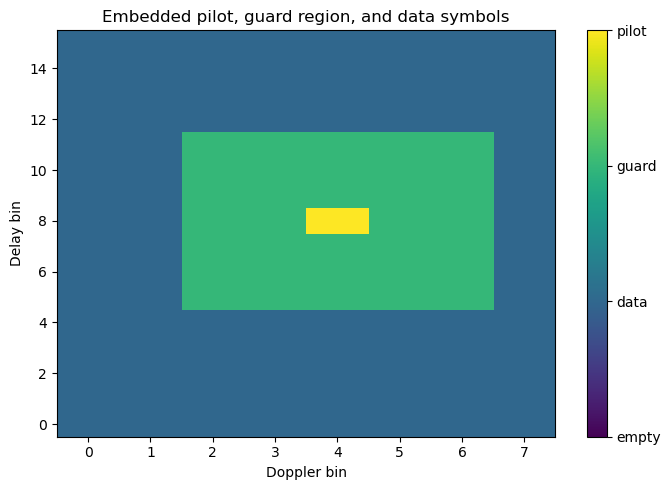

In [4]:
# ============================================================
# Visualize OTFS resource-grid structure
# ============================================================

pilot_info = pilot_pattern.pilot_info

# structure uses the plotting convention [delay, Doppler].
structure = np.zeros(
    (
        M,  # delay bins / subcarriers
        N,  # Doppler bins / OFDM symbols
    ),
    dtype=int,
)

# Sionna pilot mask shape:
# [num_tx, num_streams, num_ofdm_symbols, fft_size]
# Here:
#   axis 0 of mask_2d -> Doppler / OFDM symbol index
#   axis 1 of mask_2d -> delay / subcarrier index
# Sionna pilot mask after indexing has shape [Doppler, delay].
mask_2d = pilot_pattern.mask.numpy()[0, 0]  # [N, M]

# Data locations are the non-reserved positions.
# Data locations are all resource elements not reserved by the pilot mask.
structure[mask_2d.T == 0] = 1  # [M, N]

# Guard region from EmbeddedOTFSPilotPattern.
guard_delay_left = pilot_info["guard_delay_left"]
guard_delay_right = pilot_info["guard_delay_right"]
guard_doppler_left = pilot_info["guard_doppler_left"]
guard_doppler_right = pilot_info["guard_doppler_right"]

# Mark the rectangular guard region around the embedded pilot.
structure[
    guard_delay_left : guard_delay_right + 1,
    guard_doppler_left : guard_doppler_right + 1,
] = 2

# Pilot location.
pilot_l = pilot_info["pilot_delay_idx"]
pilot_k = pilot_info["pilot_doppler_idx"]

# Mark the single nonzero embedded pilot.
structure[pilot_l, pilot_k] = 3

plt.figure(figsize=(7, 5))

im = plt.imshow(
    structure,
    aspect="auto",
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=3,
)

plt.title("Embedded pilot, guard region, and data symbols")
plt.xlabel("Doppler bin")
plt.ylabel("Delay bin")

cbar = plt.colorbar(im)
cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels(["empty", "data", "guard", "pilot"])

plt.tight_layout()
plt.show()


## 3. Bits -> QAM -> Sionna ResourceGrid Mapper

Standard Sionna pipeline: `BinarySource` generates random information bits, `Mapper` converts groups of `NUM_BITS_PER_SYMBOL` bits to QAM constellation points, and `ResourceGridMapper` places the resulting data symbols into the non-reserved positions of the $N \times M$ delay-Doppler grid.

The output tensor `x_dd` has shape `[batch, tx, stream, N, M]`. In the delay-Doppler interpretation, `x_dd[0, 0, 0, k, l]` is the information symbol placed at Doppler bin $k$ and delay bin $\ell$.

The magnitude heatmap shows the pilot as a bright rectangle at the pilot location, the guard region as a dark zero-valued border around it, and the data symbols as uniform-magnitude QAM points across the remaining grid. The phase heatmap shows the QAM phases of the data symbols, with the guard region and pilot standing out by their distinct values.

In [5]:
# BinarySource, Mapper, and Demapper are native Sionna blocks.
binary_source = BinarySource(seed=1)
mapper = Mapper("qam", NUM_BITS_PER_SYMBOL)
demapper = Demapper("app", "qam", NUM_BITS_PER_SYMBOL)

num_data_bits = int(rg.num_data_symbols * NUM_BITS_PER_SYMBOL)
bits = binary_source([BATCH_SIZE, NUM_TX, NUM_STREAMS_PER_TX, num_data_bits])
x_data = mapper(bits)

# This is the delay-Doppler grid for OTFS.
# Shape: [batch, tx, stream, N, M]
# Map data symbols onto the OTFS delay-Doppler resource grid.
x_dd = rg_mapper(x_data)

print("bits shape: ", bits.shape)
print("x_data shape:", x_data.shape)
print("x_dd shape:  ", x_dd.shape)

bits shape:  (1, 1, 1, 186)
x_data shape: (1, 1, 1, 93)
x_dd shape:   (1, 1, 1, 8, 16)


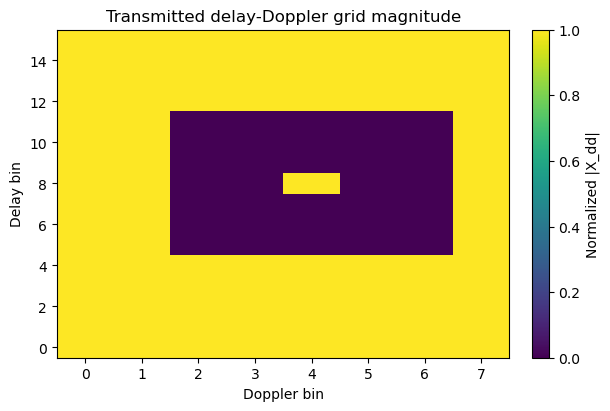

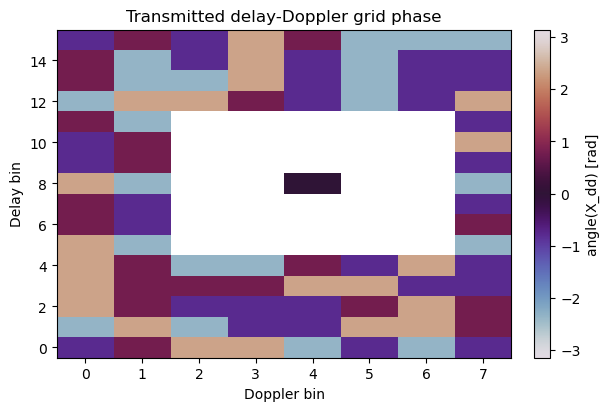

In [6]:
# Remove batch/tx/stream axes; the remaining grid is [Doppler, delay].
Xdd = x_dd.numpy()[0, 0, 0]  # [Doppler, delay]

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
# Transpose to [delay, Doppler] for plotting.
shown = np.abs(Xdd).T  # [delay, Doppler]
shown = shown / (np.max(shown) + 1e-12)
im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
ax.set_title("Transmitted delay-Doppler grid magnitude")
ax.set_xlabel("Doppler bin")
ax.set_ylabel("Delay bin")
fig.colorbar(im, ax=ax, label="Normalized |X_dd|")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
phase = masked_phase(Xdd).T  # [delay, Doppler]
im = ax.imshow(phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
ax.set_title("Transmitted delay-Doppler grid phase")
ax.set_xlabel("Doppler bin")
ax.set_ylabel("Delay bin")
fig.colorbar(im, ax=ax, label="angle(X_dd) [rad]")
plt.show()

## 4. OTFS Modulation as Precoded OFDM

OTFS modulation converts the delay-Doppler grid to a time-domain waveform in two steps.

**Step 1 -- OTFS precoding (`OTFSModulator`).** The delay-Doppler symbols $X[\ell, k]$ are transformed to time-frequency samples $X_\text{tf}[m, n]$ by the Inverse Symplectic Fast Fourier Transform (ISFFT):

$$X_\text{tf}[m, n] = \frac{1}{\sqrt{NM}} \sum_{\ell,k} X[\ell, k] \cdot e^{j2\pi\left(\frac{nk}{N} - \frac{m\ell}{M}\right)}$$

This spreads each delay-Doppler symbol uniformly across all $N$ OFDM symbols and all $M$ subcarriers. Every symbol participates in the full time-frequency extent of the frame -- the spreading that gives OTFS its diversity advantage over single-carrier or narrowband transmission.

**Step 2 -- Sionna OFDM modulation (`OFDMModulator`).** `X_tf` is processed by Sionna's standard OFDM modulator: IFFT per column followed by CP insertion. The output is the serialized CP-OFDM waveform `x_time`.

The waveform plot shows the real and imaginary parts of `x_time` with CP regions shaded.

In [7]:
# Project OTFS blocks.
# Project OTFS blocks: ISFFT for DD -> TF and SFFT for TF -> DD.
otfs_modulator = OTFSModulator()
otfs_demodulator = OTFSDemodulator()

# Sionna OFDM blocks. This is the OFDM part of "OTFS as precoded OFDM".
# Sionna OFDM blocks handle CP insertion/removal and FFT/IFFT processing.
ofdm_modulator = OFDMModulator(cyclic_prefix_length=CP_LEN)
# Use this demodulator when the input waveform still contains CP.
ofdm_demodulator_with_cp = OFDMDemodulator(
    fft_size=M,
    l_min=CHANNEL_L_MIN,
    cyclic_prefix_length=CP_LEN,
)
# Use this demodulator after time-domain LMMSE, because that output is CP-free.
ofdm_demodulator_no_cp = OFDMDemodulator(
    fft_size=M,
    l_min=CHANNEL_L_MIN,
    cyclic_prefix_length=0,
)

# OTFS precoding: delay-Doppler -> time-frequency.
# Custom OTFS precoding: delay-Doppler -> time-frequency.
x_tf = otfs_modulator(x_dd)

# Sionna OFDM modulation: time-frequency -> serialized CP waveform.
x_time = ofdm_modulator(x_tf)

print("x_tf shape:  ", x_tf.shape)
print("x_time shape:", x_time.shape)

x_tf shape:   (1, 1, 1, 8, 16)
x_time shape: (1, 1, 1, 160)


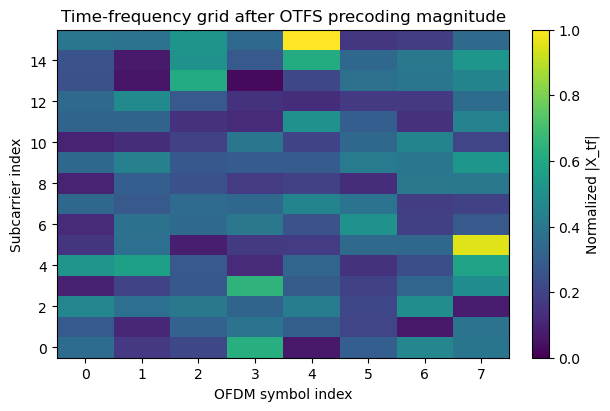

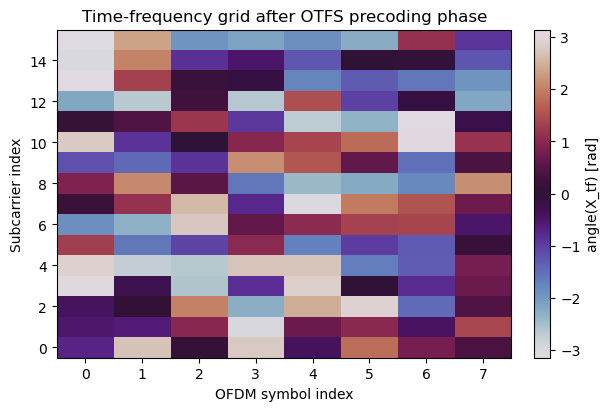

In [8]:
# Remove batch/tx/stream axes; the remaining TF grid is [OFDM symbol, subcarrier].
Xtf = x_tf.numpy()[0, 0, 0]

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
# Transpose to [subcarrier, OFDM symbol] for plotting.
shown = np.abs(Xtf).T  # [subcarrier, OFDM symbol]
shown = shown / (np.max(shown) + 1e-12)
im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
ax.set_title("Time-frequency grid after OTFS precoding magnitude")
ax.set_xlabel("OFDM symbol index")
ax.set_ylabel("Subcarrier index")
fig.colorbar(im, ax=ax, label="Normalized |X_tf|")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
phase = masked_phase(Xtf).T  # [subcarrier, OFDM symbol]
im = ax.imshow(phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
ax.set_title("Time-frequency grid after OTFS precoding phase")
ax.set_xlabel("OFDM symbol index")
ax.set_ylabel("Subcarrier index")
fig.colorbar(im, ax=ax, label="angle(X_tf) [rad]")
plt.show()

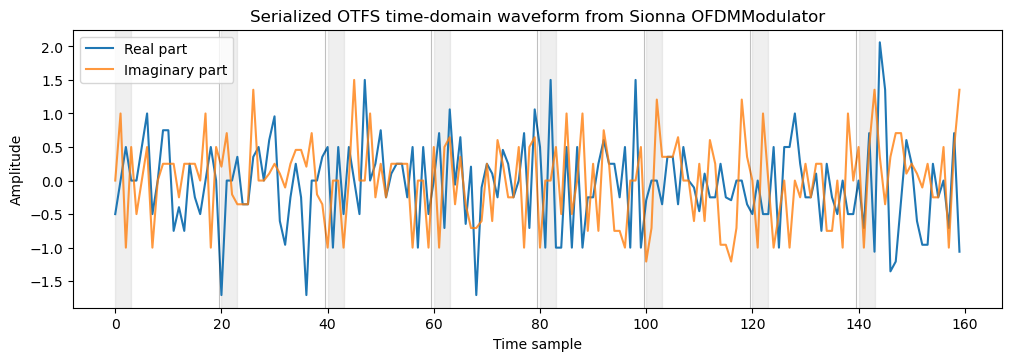

In [9]:
x_time_np = x_time.numpy()[0, 0, 0]
# One serialized waveform contains N OFDM blocks, each of length M + CP_LEN.
block_len = M + CP_LEN

fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
ax.plot(np.real(x_time_np), label="Real part")
ax.plot(np.imag(x_time_np), label="Imaginary part", alpha=0.8)
for n in range(1, N):
    ax.axvline(n * block_len - 0.5, color="black", linewidth=0.8, alpha=0.25)
for n in range(N):
    ax.axvspan(n * block_len, n * block_len + CP_LEN - 1, color="gray", alpha=0.12)
ax.set_title("Serialized OTFS time-domain waveform from Sionna OFDMModulator")
ax.set_xlabel("Time sample")
ax.set_ylabel("Amplitude")
ax.legend()
plt.show()

## 5. Channel Cases as Sionna-Compatible CIR Tensors

The same four synthetic channel cases from Notebooks 1 and 2 are reused, now generated as Sionna-compatible `(a, tau)` CIR tensors using `DDPathCIRGenerator`.

The required number of CIR time steps is slightly larger than the frame length because the channel convolution extends the signal by `CHANNEL_L_MAX` samples. `get_required_num_cir_time_steps` handles this padding automatically.

In [10]:
# Define simple DD-path channels directly through gain, delay tap, and Doppler tap.
channel_cases = {
    "Static multipath": {
        "g_i": np.array([1.0 + 0.0j, 0.55 + 0.25j, 0.35 - 0.15j], dtype=np.complex64),
        "l_i": np.array([0, 2, 3], dtype=np.int32),
        "k_i": np.array([0.0, 0.0, 0.0], dtype=np.float32),
    },
    "Pure Doppler": {
        "g_i": np.array([1.0 + 0.0j, 0.60 + 0.20j], dtype=np.complex64),
        "l_i": np.array([0, 0], dtype=np.int32),
        "k_i": np.array([0.0, 2.0], dtype=np.float32),
    },
    "Doubly dispersive": {
        "g_i": np.array([1.0 + 0.0j, 0.55 + 0.25j, 0.35 - 0.15j], dtype=np.complex64),
        "l_i": np.array([0, 2, 3], dtype=np.int32),
        "k_i": np.array([0.0, 1.0, -2.0], dtype=np.float32),
    },
    "Fractional Doppler": {
        "g_i": np.array([1.0 + 0.0j, 0.55 + 0.25j, 0.35 - 0.15j], dtype=np.complex64),
        "l_i": np.array([0, 2, 3], dtype=np.int32),
        "k_i": np.array([0.0, 1.5, -2.3], dtype=np.float32),
    },
}

# The CIR needs enough time steps for Sionna's time-domain channel application.
num_time_steps = get_required_num_cir_time_steps(
    num_time_samples=rg.num_time_samples,
    l_min=CHANNEL_L_MIN,
    l_max=CHANNEL_L_MAX,
)

channel_data = {}

for name, paths in channel_cases.items():
    # Convert each DD-path model into Sionna-compatible CIR tensors a and tau.
    generator = DDPathCIRGenerator(
        g_i=paths["g_i"],
        l_i=paths["l_i"],
        k_i=paths["k_i"],
    )

    a, tau = generator(
        batch_size=BATCH_SIZE,
        num_time_steps=num_time_steps,
        bandwidth=rg.bandwidth,
    )

    channel_data[name] = {
        **paths,
        "a": a,
        "tau": tau,
    }

    print("=" * 70)
    print(name)
    print("a shape:  ", a.shape)
    print("tau shape:", tau.shape)
    print("g_i:", paths["g_i"])
    print("l_i:", paths["l_i"])
    print("k_i:", paths["k_i"])

Static multipath
a shape:   (1, 1, 1, 1, 1, 3, 163)
tau shape: (1, 1, 1, 3)
g_i: [1.  +0.j   0.55+0.25j 0.35-0.15j]
l_i: [0 2 3]
k_i: [0. 0. 0.]
Pure Doppler
a shape:   (1, 1, 1, 1, 1, 2, 163)
tau shape: (1, 1, 1, 2)
g_i: [1. +0.j  0.6+0.2j]
l_i: [0 0]
k_i: [0. 2.]
Doubly dispersive
a shape:   (1, 1, 1, 1, 1, 3, 163)
tau shape: (1, 1, 1, 3)
g_i: [1.  +0.j   0.55+0.25j 0.35-0.15j]
l_i: [0 2 3]
k_i: [ 0.  1. -2.]
Fractional Doppler
a shape:   (1, 1, 1, 1, 1, 3, 163)
tau shape: (1, 1, 1, 3)
g_i: [1.  +0.j   0.55+0.25j 0.35-0.15j]
l_i: [0 2 3]
k_i: [ 0.   1.5 -2.3]


## 6. Apply Channel, AWGN, and Perfect-CSI Block LMMSE

The received signal passes through three stages.

**`ApplyCIRTimeChannel`** converts the `(a, tau)` CIR tensor to the time-domain channel `h_time` and applies it as a convolution to `x_time`. The extra samples produced by the convolution tail are absorbed internally and the output length matches `rg.num_time_samples`.

**`AWGN`** adds complex Gaussian noise at the specified Eb/N0.

Two receiver paths are then compared:

**No equalization:** `OFDMDemodulator` (with CP removal) followed by `OTFSDemodulator` (SFFT) and `ResourceGridDemapper`, with no channel correction applied. This shows the raw distortion introduced by the channel.

**Perfect-CSI block LMMSE:** the true delay-time channel `gs_true` is extracted from `h_time` via `h_time_to_gs` and passed to `BlockLMMSEEqualizer`. For each of the $N$ CP-OFDM blocks, the equalizer solves:

$$\hat{s}_n = \left(G_n^H G_n + \sigma_w^2 I\right)^{-1} G_n^H r_n$$

where $G_n$ is the $M \times M$ block channel matrix constructed from `gs` and $r_n$ is the received block. The equalizer output is CP-free, so the subsequent OFDM demodulation uses the no-CP `OFDMDemodulator` variant.

In [11]:
# ApplyCIRTimeChannel wraps Sionna's time-domain channel using the generated a,tau tensors.
channel = ApplyCIRTimeChannel(
    bandwidth=rg.bandwidth,
    l_min=CHANNEL_L_MIN,
    l_max=CHANNEL_L_MAX,
    normalize=CHANNEL_NORMALIZE,
)

awgn = AWGN()
# BlockLMMSEEqualizer uses the delay-time channel gs, not the raw CIR tensors.
block_lmmse = BlockLMMSEEqualizer(
    num_blocks=N,
    fft_size=M,
    cyclic_prefix_length=CP_LEN,
)

# Convert Eb/N0 into the noise variance used by AWGN and the LMMSE equalizer.
no = ebnodb2no(
    EBNO_DB,
    NUM_BITS_PER_SYMBOL,
    CODERATE_FOR_NO,
    rg,
) * NUM_BITS_PER_SYMBOL

print("Noise variance no:", no.numpy() if hasattr(no, "numpy") else no)

for name, data in channel_data.items():
    y_time, h_time = channel(x_time, data["a"], data["tau"])
    y_time_noisy = awgn(y_time, no)

    # No equalization receiver.
    # Receiver without equalization: CP removal + OFDM demodulation + OTFS demodulation.
    y_tf_no_eq = ofdm_demodulator_with_cp(y_time_noisy)
    y_dd_no_eq = otfs_demodulator(y_tf_no_eq)
    x_hat_no_eq = rg_demapper(y_dd_no_eq)

    # Perfect CSI receiver.
    # Use the true h_time, convert it to textbook gs, and equalize in the time domain.
    # Perfect-CSI receiver: extract the true delay-time channel used by the equalizer.
    gs_true = h_time_to_gs(h_time, rg.num_time_samples)
    # The LMMSE equalizer operates in the time domain and returns a CP-free waveform.
    y_time_lmmse = block_lmmse(y_time_noisy, gs_true, no)

    # The LMMSE output is CP-free, so use the no-CP OFDM demodulator.
    # Because y_time_lmmse is CP-free, use the no-CP OFDM demodulator.
    y_tf_lmmse = ofdm_demodulator_no_cp(y_time_lmmse)
    y_dd_lmmse = otfs_demodulator(y_tf_lmmse)
    x_hat_lmmse = rg_demapper(y_dd_lmmse)

    data["y_time"] = y_time
    data["y_time_noisy"] = y_time_noisy
    data["h_time"] = h_time
    data["gs_true"] = gs_true

    data["y_tf_no_eq"] = y_tf_no_eq
    data["y_dd_no_eq"] = y_dd_no_eq
    data["x_hat_no_eq"] = x_hat_no_eq

    data["y_time_lmmse"] = y_time_lmmse
    data["y_tf_lmmse"] = y_tf_lmmse
    data["y_dd_lmmse"] = y_dd_lmmse
    data["x_hat_lmmse"] = x_hat_lmmse

    print("=" * 70)
    print(name)
    print("y_time shape:      ", y_time.shape)
    print("h_time shape:      ", h_time.shape)
    print("gs_true shape:     ", gs_true.shape)
    print("y_dd_no_eq shape:  ", y_dd_no_eq.shape)
    print("y_dd_lmmse shape:  ", y_dd_lmmse.shape)

Noise variance no: 0.0017204301
Static multipath
y_time shape:       (1, 1, 1, 163)
h_time shape:       (1, 1, 1, 1, 1, 163, 4)
gs_true shape:      (4, 160)
y_dd_no_eq shape:   (1, 1, 1, 8, 16)
y_dd_lmmse shape:   (1, 1, 1, 8, 16)
Pure Doppler
y_time shape:       (1, 1, 1, 163)
h_time shape:       (1, 1, 1, 1, 1, 163, 4)
gs_true shape:      (4, 160)
y_dd_no_eq shape:   (1, 1, 1, 8, 16)
y_dd_lmmse shape:   (1, 1, 1, 8, 16)
Doubly dispersive
y_time shape:       (1, 1, 1, 163)
h_time shape:       (1, 1, 1, 1, 1, 163, 4)
gs_true shape:      (4, 160)
y_dd_no_eq shape:   (1, 1, 1, 8, 16)
y_dd_lmmse shape:   (1, 1, 1, 8, 16)
Fractional Doppler
y_time shape:       (1, 1, 1, 163)
h_time shape:       (1, 1, 1, 1, 1, 163, 4)
gs_true shape:      (4, 160)
y_dd_no_eq shape:   (1, 1, 1, 8, 16)
y_dd_lmmse shape:   (1, 1, 1, 8, 16)


## 7. Discrete Time-Varying Channel Taps

The discrete channel `h_time[q, l]` for the four cases, at the scale of the full OTFS frame.

The magnitude plots show active delay taps as flat horizontal bands -- the same structure seen in Notebook 1, now extended over the full frame duration. The phase plots show the Doppler-induced phase ramp across the frame: for the doubly dispersive and fractional Doppler cases, the phase at each active tap completes a rotation whose rate depends on the Doppler tap value $\kappa_i$.

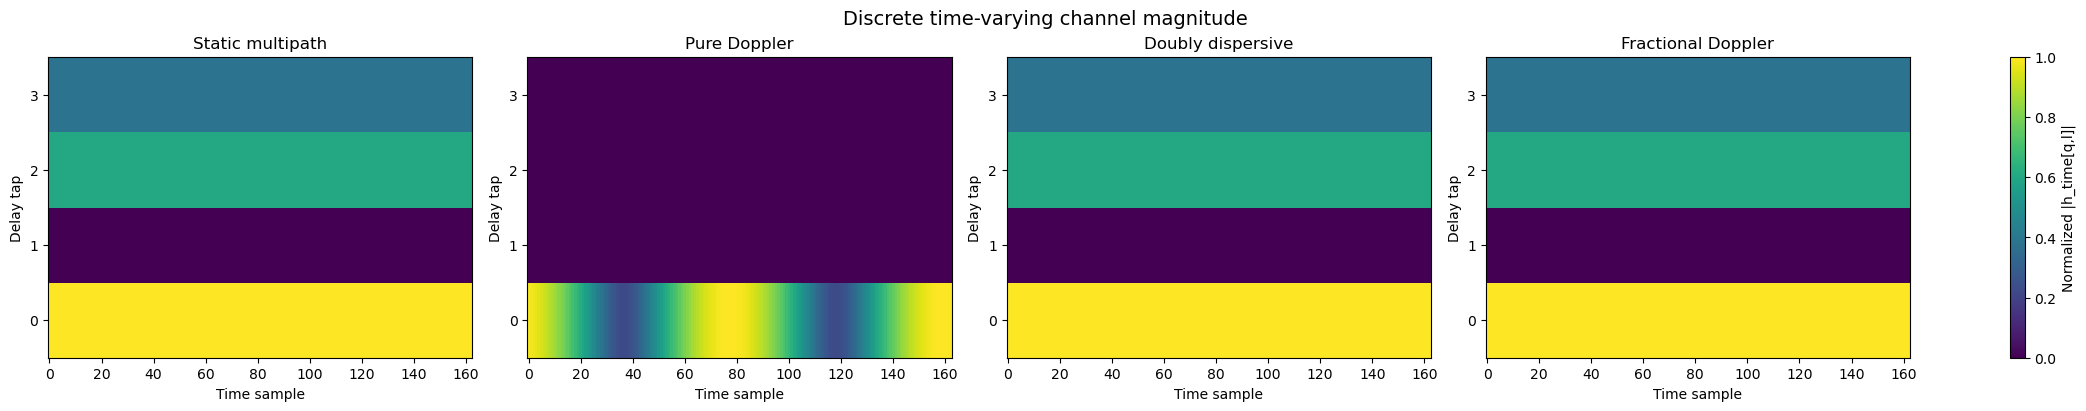

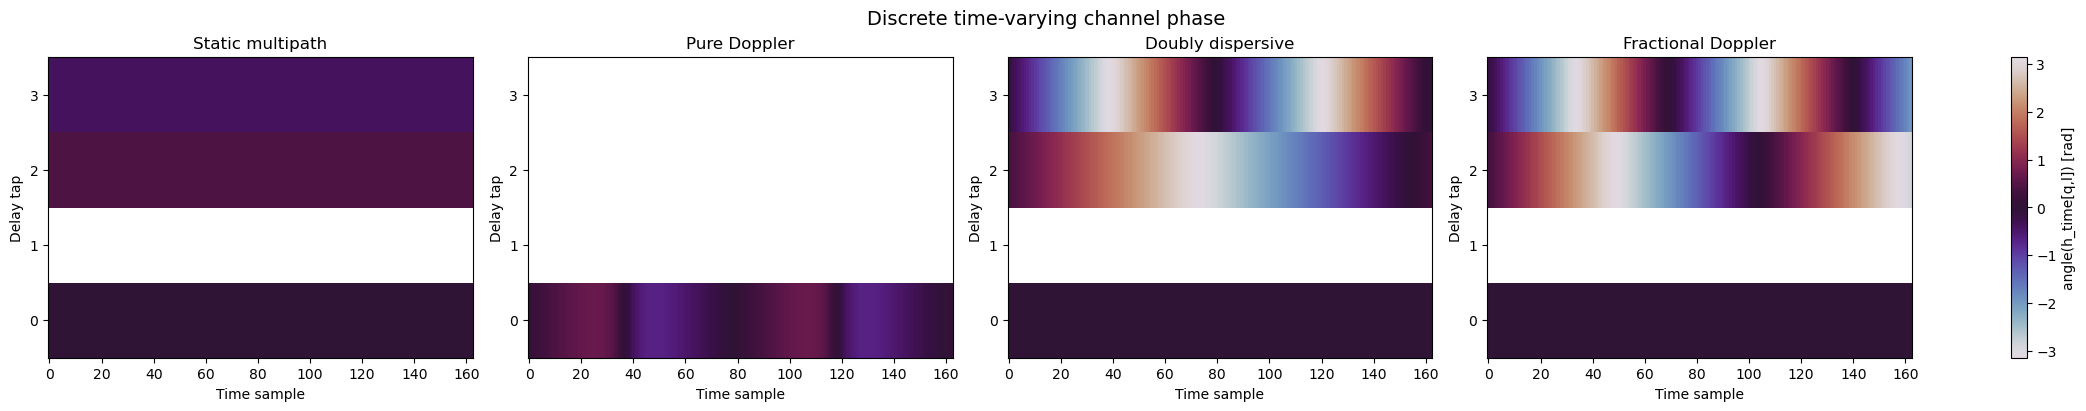

In [12]:
fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    # h_time after indexing is [time, delay].
    h = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]
    # Transpose to [delay, time] for plotting.
    h_abs = np.abs(h).T
    h_abs = h_abs / (np.max(h_abs) + 1e-12)

    im = ax.imshow(h_abs, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Delay tap")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="Normalized |h_time[q,l]|")
fig.suptitle("Discrete time-varying channel magnitude", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    h = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]
    phase = masked_phase(h).T

    im = ax.imshow(phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Delay tap")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="angle(h_time[q,l]) [rad]")
fig.suptitle("Discrete time-varying channel phase", fontsize=14)
plt.show()

## 8. Received TF Grids before Equalization

The received time-frequency grids $Y_\text{tf}$ before any channel correction.

For the static multipath channel the grid shows a time-invariant magnitude pattern -- frequency-selective fading with the same gain profile at every OFDM symbol. This is the condition under which single-tap OFDM equalization is effective.

For the Doppler and doubly dispersive channels the magnitude pattern changes from symbol to symbol, and the phase plot shows visible spreading across the time axis. The pilot region is visible as a bright stripe at the guard delay bins -- its energy is concentrated in one grid position in the delay-Doppler domain, which after the ISFFT precoding spreads out in frequency but remains coherent.

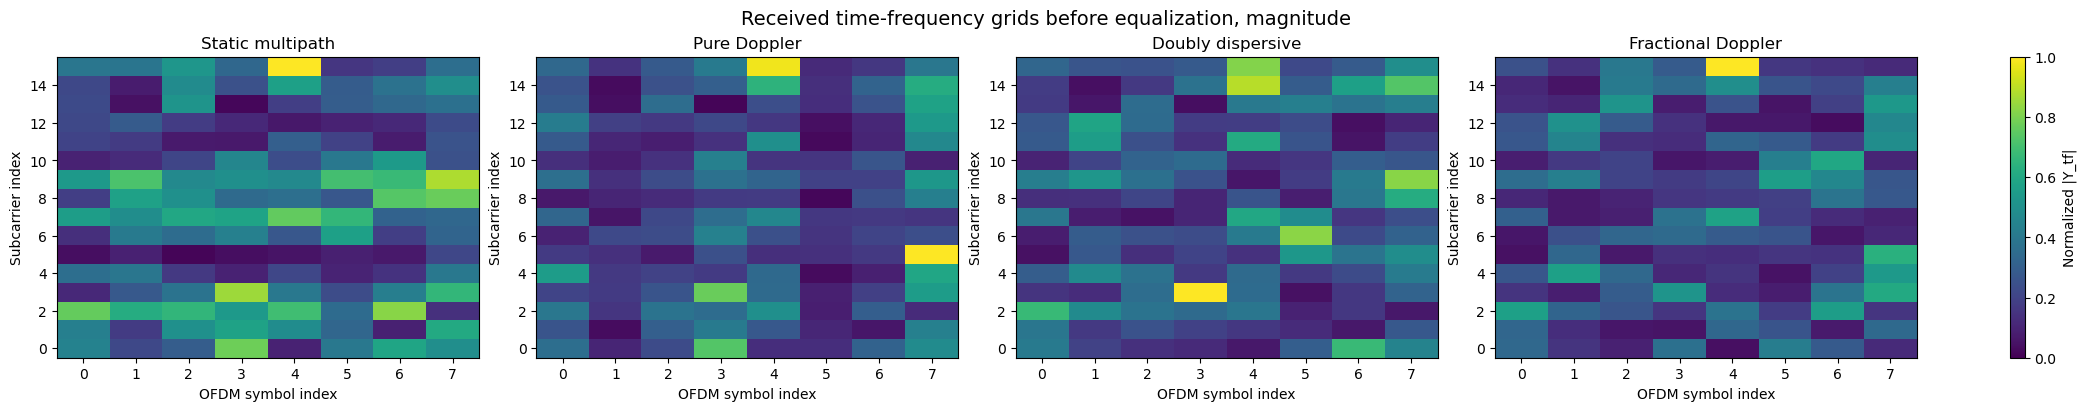

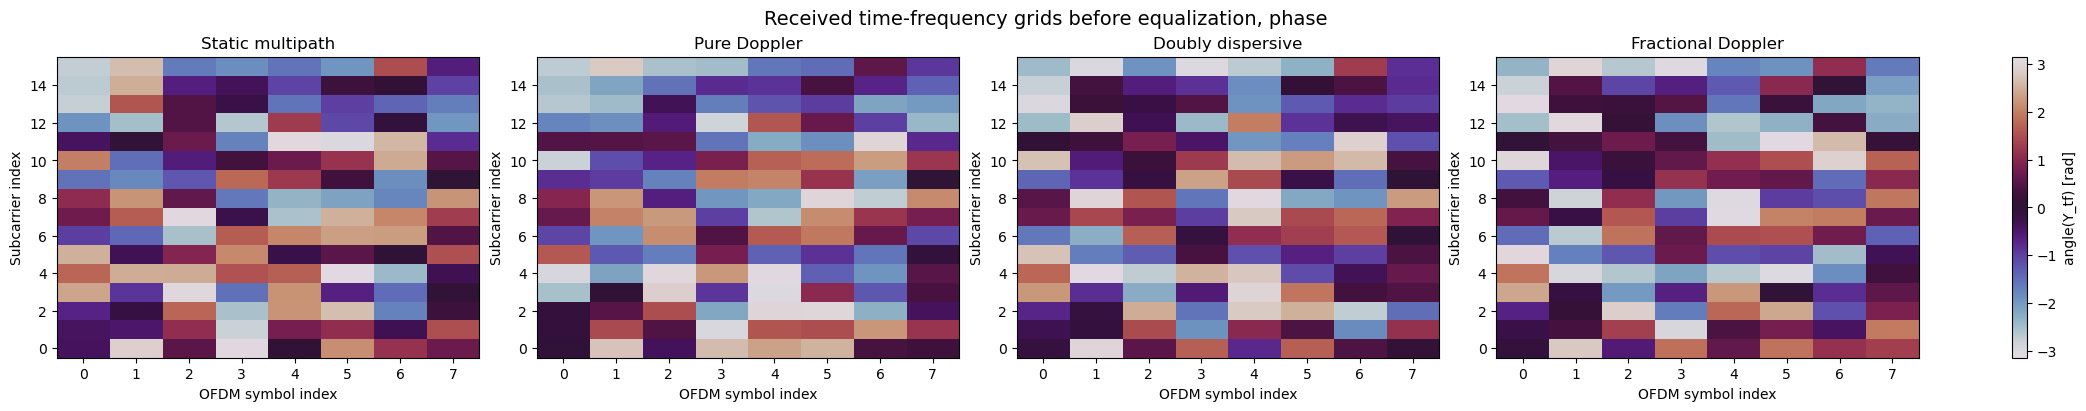

In [13]:
fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    # y_tf_no_eq is the received time-frequency grid before equalization.
    Ytf = data["y_tf_no_eq"].numpy()[0, 0, 0]
    shown = np.abs(Ytf).T  # [subcarrier, OFDM symbol]
    shown = shown / (np.max(shown) + 1e-12)

    im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xlabel("OFDM symbol index")
    ax.set_ylabel("Subcarrier index")

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="Normalized |Y_tf|")
fig.suptitle("Received time-frequency grids before equalization, magnitude", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    Ytf = data["y_tf_no_eq"].numpy()[0, 0, 0]
    phase = masked_phase(Ytf).T  # [subcarrier, OFDM symbol]

    im = ax.imshow(phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    ax.set_title(name)
    ax.set_xlabel("OFDM symbol index")
    ax.set_ylabel("Subcarrier index")

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="angle(Y_tf) [rad]")
fig.suptitle("Received time-frequency grids before equalization, phase", fontsize=14)
plt.show()

## 9. Received DD Grids before Equalization

After the SFFT (OTFS demodulation), the received delay-Doppler grid $Y_\text{dd}$ shows the effect of the channel in the domain OTFS operates in.

For the static multipath channel the grid is a shifted and scaled version of the transmitted $X_\text{dd}$: multipath echoes move energy to different delay bins while keeping it at the same Doppler bins.

For Doppler channels the energy spreads in both delay and Doppler, with off-diagonal structure reflecting the channel's delay-Doppler response. The fractional Doppler case shows the most severe smearing, from the sinc leakage discussed in Notebook 1.

The pilot and guard region are clearly visible as an isolated bright region surrounded by zeros -- the guard is working as intended, keeping the pilot response separated from the data.

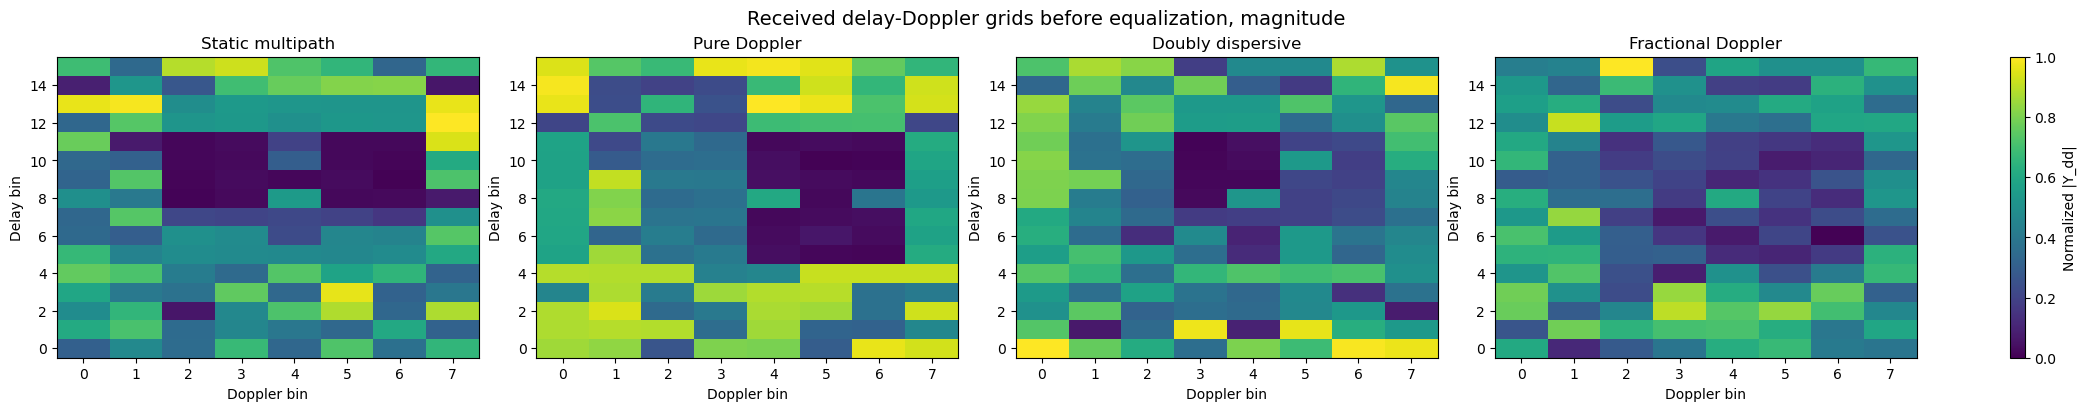

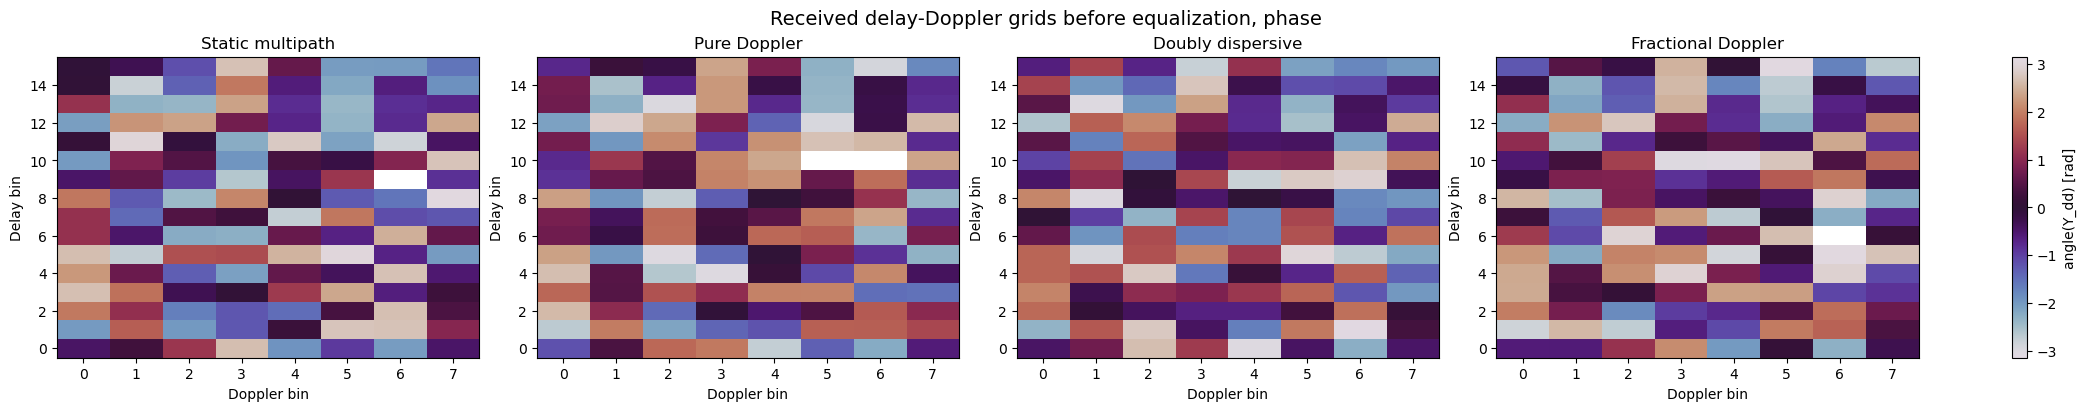

In [14]:
fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    # y_dd_no_eq is the received delay-Doppler grid before equalization.
    Ydd = data["y_dd_no_eq"].numpy()[0, 0, 0]  # [Doppler, delay]
    shown = np.abs(Ydd).T  # [delay, Doppler]
    shown = shown / (np.max(shown) + 1e-12)

    im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xlabel("Doppler bin")
    ax.set_ylabel("Delay bin")

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="Normalized |Y_dd|")
fig.suptitle("Received delay-Doppler grids before equalization, magnitude", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    Ydd = data["y_dd_no_eq"].numpy()[0, 0, 0]  # [Doppler, delay]
    phase = masked_phase(Ydd).T  # [delay, Doppler]

    im = ax.imshow(phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    ax.set_title(name)
    ax.set_xlabel("Doppler bin")
    ax.set_ylabel("Delay bin")

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="angle(Y_dd) [rad]")
fig.suptitle("Received delay-Doppler grids before equalization, phase", fontsize=14)
plt.show()

## 10. Received DD Grids after Perfect-CSI LMMSE

With perfect channel knowledge and block LMMSE equalization, the received delay-Doppler grids recover the structure of the transmitted $X_\text{dd}$: data symbols appear at their correct positions and the guard region is largely zeroed out.

Comparing the pre- and post-equalization grids confirms that the block LMMSE successfully inverts the channel for all four cases when the channel delay is within the modelled range (`CHANNEL_L_MAX` $\geq max(\ell_i)$).

The fractional Doppler case shows slightly more residual distortion than the others, because the block LMMSE constructs integer-tap matrices from `gs` and cannot perfectly represent the continuous Doppler offset.

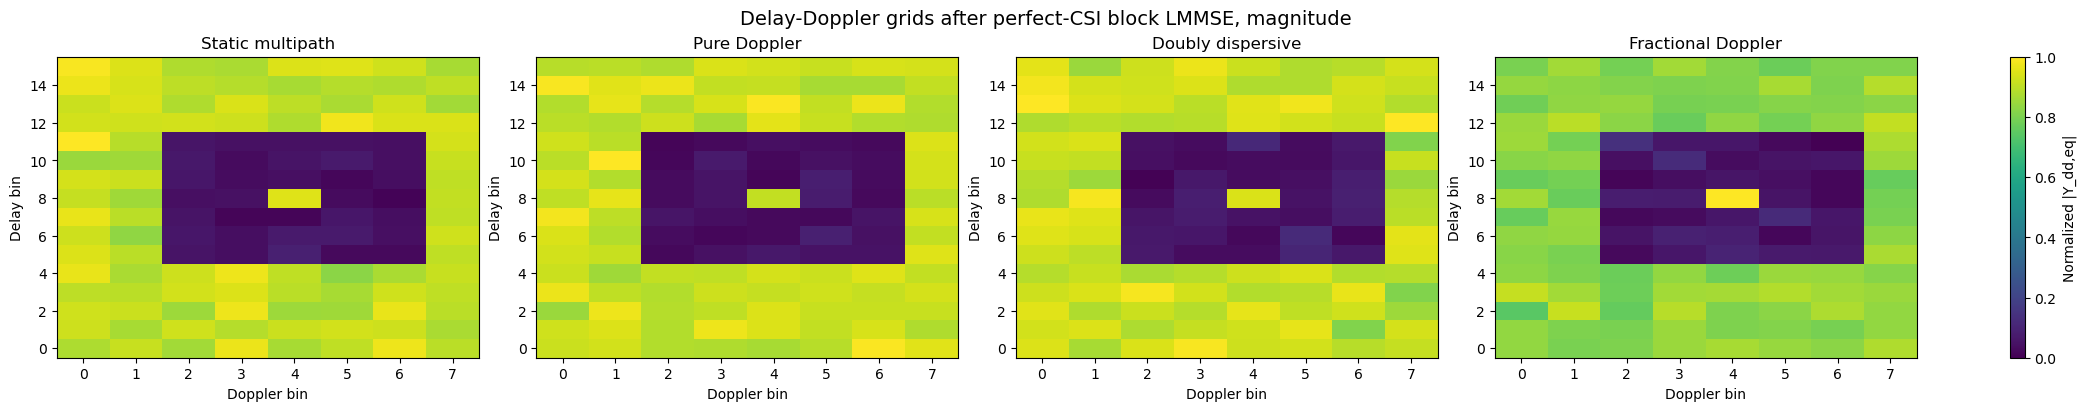

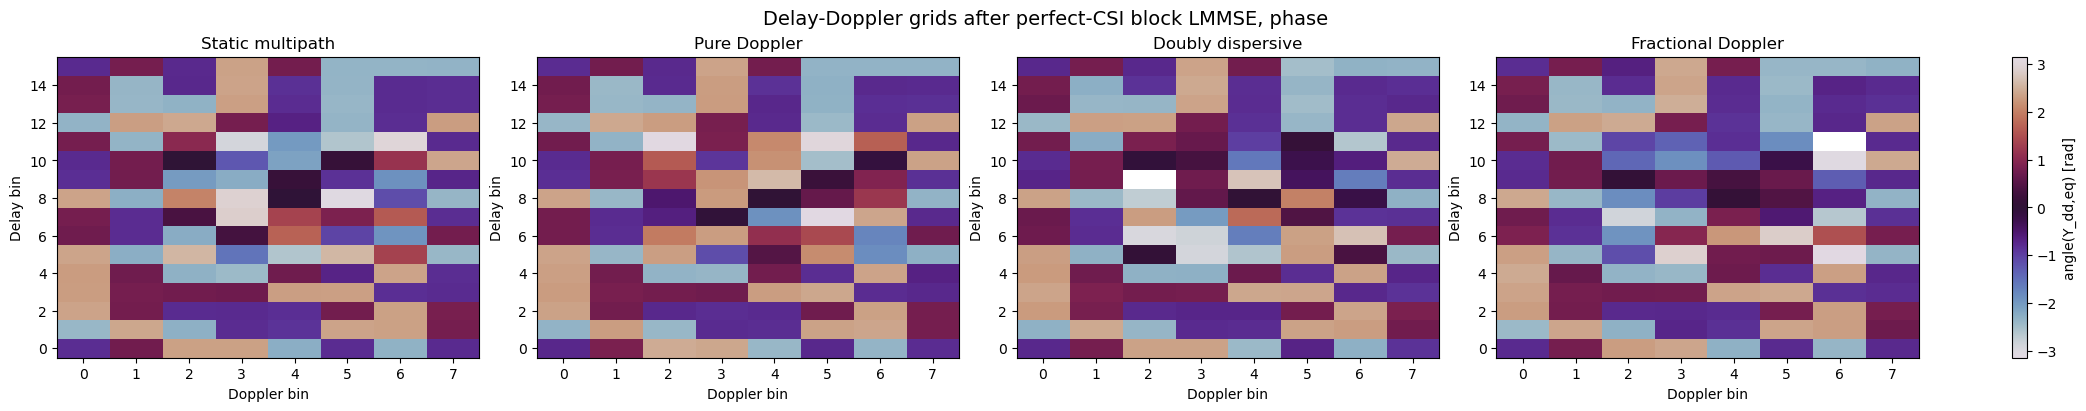

In [15]:
fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    # y_dd_lmmse is the received delay-Doppler grid after perfect-CSI LMMSE.
    Ydd = data["y_dd_lmmse"].numpy()[0, 0, 0]  # [Doppler, delay]
    shown = np.abs(Ydd).T  # [delay, Doppler]
    shown = shown / (np.max(shown) + 1e-12)

    im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xlabel("Doppler bin")
    ax.set_ylabel("Delay bin")

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="Normalized |Y_dd,eq|")
fig.suptitle("Delay-Doppler grids after perfect-CSI block LMMSE, magnitude", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    Ydd = data["y_dd_lmmse"].numpy()[0, 0, 0]  # [Doppler, delay]
    phase = masked_phase(Ydd).T  # [delay, Doppler]

    im = ax.imshow(phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    ax.set_title(name)
    ax.set_xlabel("Doppler bin")
    ax.set_ylabel("Delay bin")

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="angle(Y_dd,eq) [rad]")
fig.suptitle("Delay-Doppler grids after perfect-CSI block LMMSE, phase", fontsize=14)
plt.show()

## 11. DD Impulse through the Same Sionna-Compatible Chain

A single unit impulse placed at the centre of the delay-Doppler grid is transmitted through the full pipeline to visualize the channel's delay-Doppler spreading function empirically.

The transmitted impulse appears as a single bright pixel. The received response shows how the channel spreads that pixel:

- **Static multipath:** copies appear at delay offsets $\ell_i$ above the impulse position, all at the same Doppler bin.
- **Pure Doppler:** copies appear at Doppler offsets $\kappa_i$ from the impulse position, all at the same delay bin.
- **Doubly dispersive:** copies are offset in both delay and Doppler, each at position $(\ell_i, \kappa_i)$ relative to the input.
- **Fractional Doppler:** copies are smeared across multiple Doppler bins due to sinc leakage, consistent with the analysis in Notebook 1.

This is an empirical verification that the implementation's effective delay-Doppler channel matches the theoretical description.

In [16]:
# Create a single DD impulse to see how one DD symbol spreads through the full chain.
x_dd_impulse_np = np.zeros((BATCH_SIZE, NUM_TX, NUM_STREAMS_PER_TX, N, M), dtype=np.complex64)
impulse_doppler_idx = N // 2
impulse_delay_idx = M // 2
x_dd_impulse_np[0, 0, 0, impulse_doppler_idx, impulse_delay_idx] = 1.0 + 0.0j
x_dd_impulse = tf.constant(x_dd_impulse_np, dtype=tf.complex64)

# Pass the impulse through the same OTFS -> OFDM -> channel -> OFDM -> OTFS chain.
x_tf_impulse = otfs_modulator(x_dd_impulse)
x_time_impulse = ofdm_modulator(x_tf_impulse)

for name, data in channel_data.items():
    y_time_impulse, _ = channel(x_time_impulse, data["a"], data["tau"])
    y_tf_impulse = ofdm_demodulator_with_cp(y_time_impulse)
    y_dd_impulse = otfs_demodulator(y_tf_impulse)
    data["y_dd_impulse"] = y_dd_impulse

print("Impulse propagation completed.")

Impulse propagation completed.


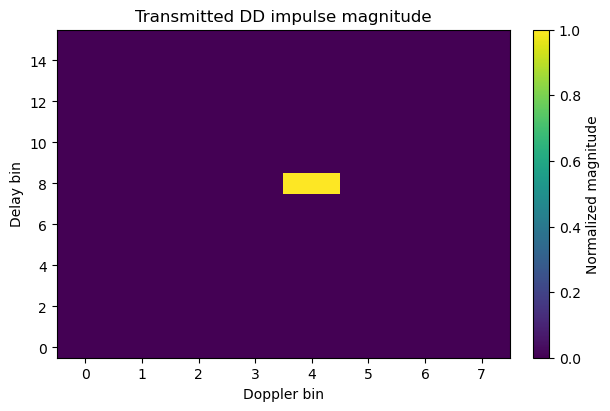

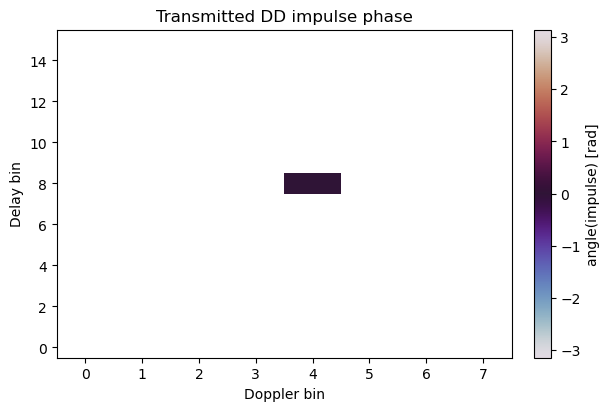

In [17]:
Ximp = x_dd_impulse.numpy()[0, 0, 0]  # [Doppler, delay]

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
shown = np.abs(Ximp).T  # [delay, Doppler]
shown = shown / (np.max(shown) + 1e-12)
im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
ax.set_title("Transmitted DD impulse magnitude")
ax.set_xlabel("Doppler bin")
ax.set_ylabel("Delay bin")
fig.colorbar(im, ax=ax, label="Normalized magnitude")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
phase = masked_phase(Ximp).T  # [delay, Doppler]
im = ax.imshow(phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
ax.set_title("Transmitted DD impulse phase")
ax.set_xlabel("Doppler bin")
ax.set_ylabel("Delay bin")
fig.colorbar(im, ax=ax, label="angle(impulse) [rad]")
plt.show()

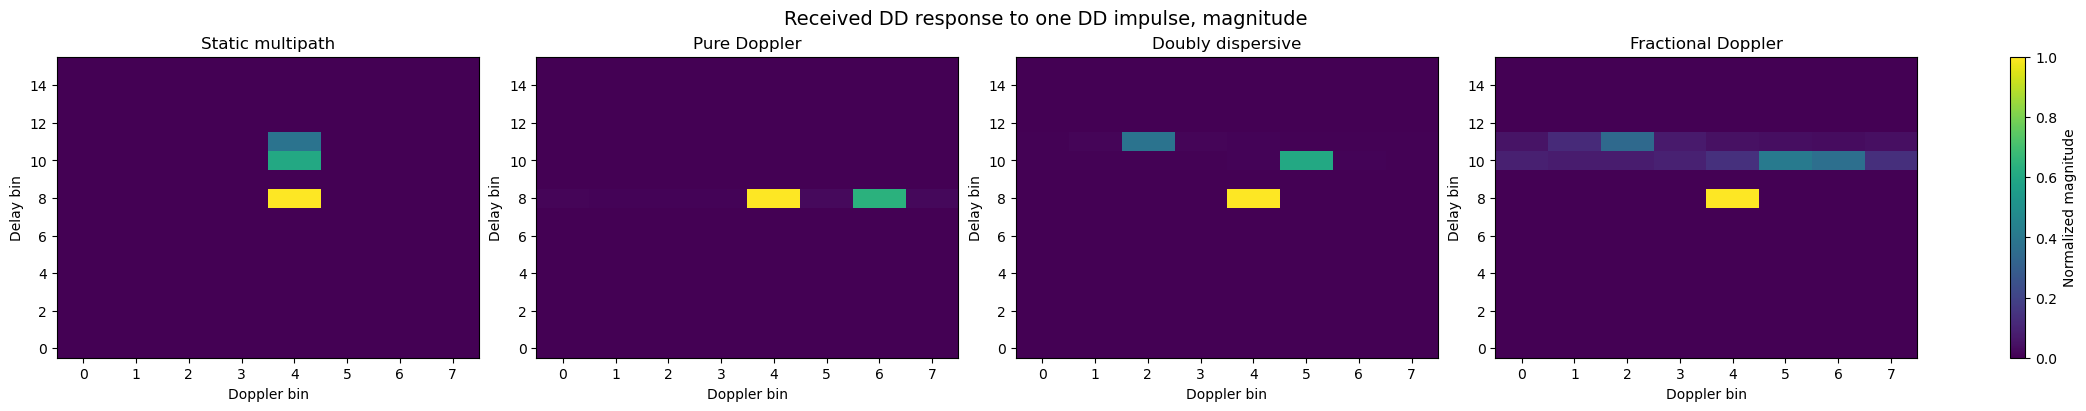

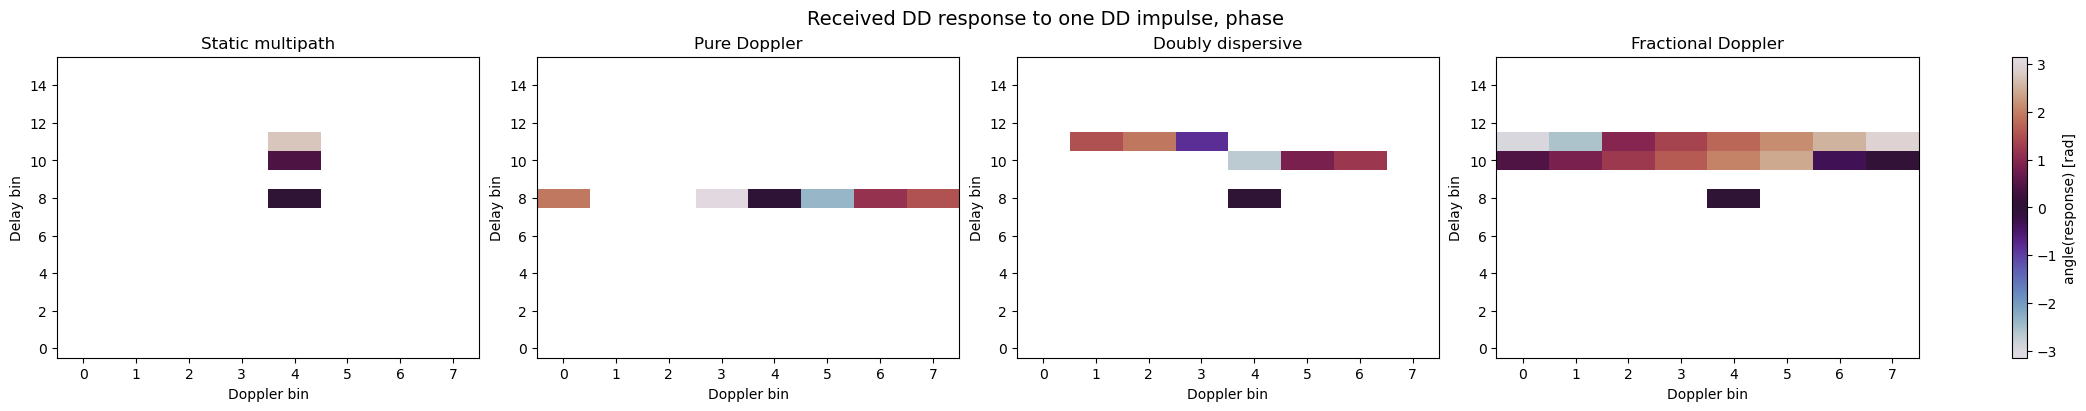

In [18]:
fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    Ydd = data["y_dd_impulse"].numpy()[0, 0, 0]  # [Doppler, delay]
    shown = np.abs(Ydd).T  # [delay, Doppler]
    shown = shown / (np.max(shown) + 1e-12)

    im = ax.imshow(shown, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(name)
    ax.set_xlabel("Doppler bin")
    ax.set_ylabel("Delay bin")

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="Normalized magnitude")
fig.suptitle("Received DD response to one DD impulse, magnitude", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(channel_data), figsize=(5.2 * len(channel_data), 4), constrained_layout=True)
if len(channel_data) == 1:
    axes = [axes]

for ax, (name, data) in zip(axes, channel_data.items()):
    Ydd = data["y_dd_impulse"].numpy()[0, 0, 0]  # [Doppler, delay]
    phase = masked_phase(Ydd).T  # [delay, Doppler]

    im = ax.imshow(phase, aspect="auto", origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    ax.set_title(name)
    ax.set_xlabel("Doppler bin")
    ax.set_ylabel("Delay bin")

fig.colorbar(im, ax=np.ravel(axes).tolist(), label="angle(response) [rad]")
fig.suptitle("Received DD response to one DD impulse, phase", fontsize=14)
plt.show()

## 12. Effective DD Channel Matrix from Implementation Probing

The effective $NM \times NM$ delay-Doppler channel matrix $H_\text{eff}$ is probed column by column: one DD basis symbol is transmitted, propagated through the full implementation chain, and the received DD vector forms one column of $H_\text{eff}$.

This is computationally expensive -- one forward pass per grid position -- but produces the exact channel matrix that the implementation uses, with no analytical approximation.

The resulting matrices show several structural features:

**Banded structure:** non-zero entries appear only near the block sub-diagonals, reflecting the delay spread. The bandwidth of the matrix is set by the maximum delay tap relative to the Doppler resolution.

**Circulant sub-blocks:** for the static multipath case each $N \times N$ block of the matrix is approximately circulant. For Doppler channels the circulant structure within blocks is broken, consistent with the analysis in Notebook 2.

**Phase patterns:** the phase plots reveal the Doppler-induced phase rotation along each block sub-diagonal. For doubly dispersive channels the phase evolves smoothly along the diagonal direction, encoding the Doppler tap value as a spatial frequency across the matrix.

In [19]:
# This section probes the actual implementation chain one DD basis vector at a time.
# It is meant for visualization, not for fast simulation.
#
# The same probing operation is performed for every channel case so the
# effective DD-domain matrix structure can be compared across scenarios.
# Keep this switch explicit because this probing cell is slow.
BUILD_EFFECTIVE_DD_MATRIX = True

if BUILD_EFFECTIVE_DD_MATRIX:
    MN = M * N

    for name, data in channel_data.items():
        H_eff_dd = np.zeros((MN, MN), dtype=np.complex64)

        for col in range(MN):
            # Flattening convention: col = doppler_idx * M + delay_idx.
            doppler_idx = col // M
            delay_idx = col % M

            x_basis_np = np.zeros(
                (BATCH_SIZE, NUM_TX, NUM_STREAMS_PER_TX, N, M),
                dtype=np.complex64,
            )
            x_basis_np[0, 0, 0, doppler_idx, delay_idx] = 1.0 + 0.0j
            x_basis = tf.constant(x_basis_np, dtype=tf.complex64)

            x_tf_basis = otfs_modulator(x_basis)
            x_time_basis = ofdm_modulator(x_tf_basis)
            y_time_basis, _ = channel(x_time_basis, data["a"], data["tau"])
            y_tf_basis = ofdm_demodulator_with_cp(y_time_basis)
            y_dd_basis = otfs_demodulator(y_tf_basis)

            # Vectorization convention: [Doppler, delay] flattened row-wise.
            # Each received DD basis response becomes one column of H_eff_dd.
            H_eff_dd[:, col] = y_dd_basis.numpy()[0, 0, 0].reshape(-1)

        data["H_eff_dd"] = H_eff_dd
        print(f"Built H_eff_dd for {name}: {H_eff_dd.shape}")


Built H_eff_dd for Static multipath: (128, 128)
Built H_eff_dd for Pure Doppler: (128, 128)
Built H_eff_dd for Doubly dispersive: (128, 128)
Built H_eff_dd for Fractional Doppler: (128, 128)


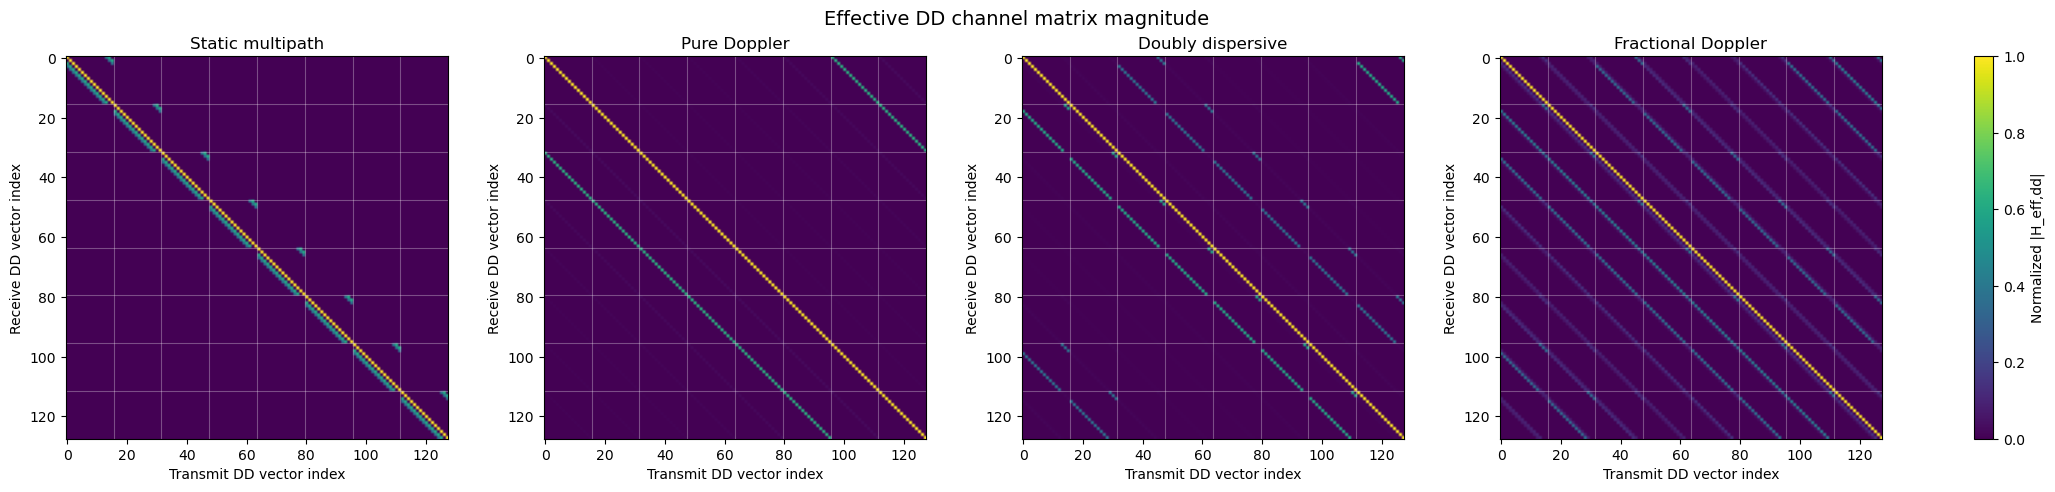

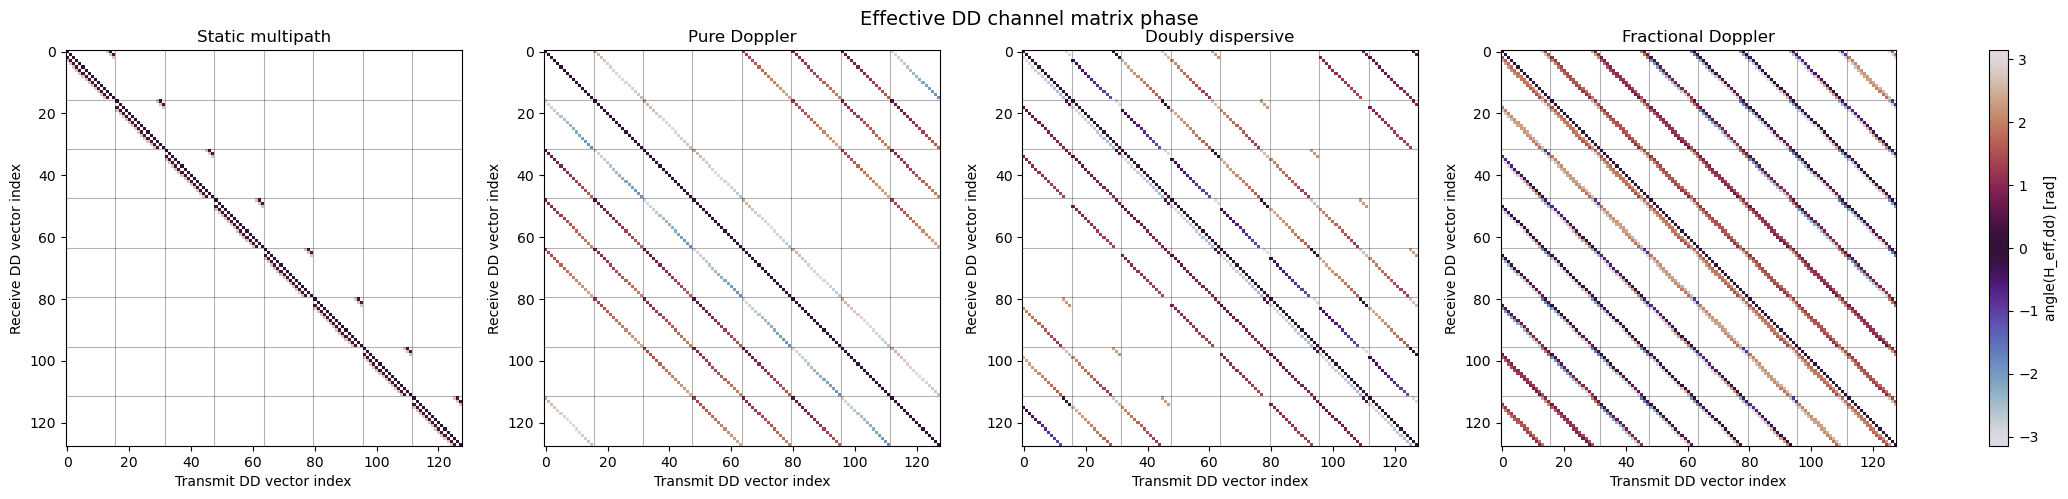

In [20]:
if BUILD_EFFECTIVE_DD_MATRIX:
    fig, axes = plt.subplots(
        1,
        len(channel_data),
        figsize=(5.2 * len(channel_data), 4.8),
        constrained_layout=True,
    )
    if len(channel_data) == 1:
        axes = [axes]

    for ax, (name, data) in zip(axes, channel_data.items()):
        H = data["H_eff_dd"]
        H_abs = np.abs(H)
        H_abs = H_abs / (np.max(H_abs) + 1e-12)

        im = ax.imshow(
            H_abs,
            aspect="equal",
            origin="upper",
            cmap="viridis",
            vmin=0,
            vmax=1,
        )

        for b in range(1, N):
            pos = b * M
            ax.axvline(pos - 0.5, color="white", linewidth=0.8, alpha=0.3)
            ax.axhline(pos - 0.5, color="white", linewidth=0.8, alpha=0.3)

        ax.set_title(name)
        ax.set_xlabel("Transmit DD vector index")
        ax.set_ylabel("Receive DD vector index")

    fig.colorbar(
        im,
        ax=np.ravel(axes).tolist(),
        label="Normalized |H_eff,dd|",
    )
    fig.suptitle("Effective DD channel matrix magnitude", fontsize=14)
    plt.show()

    fig, axes = plt.subplots(
        1,
        len(channel_data),
        figsize=(5.2 * len(channel_data), 4.8),
        constrained_layout=True,
    )
    if len(channel_data) == 1:
        axes = [axes]

    for ax, (name, data) in zip(axes, channel_data.items()):
        H = data["H_eff_dd"]
        phase = masked_phase(H)

        im = ax.imshow(
            phase,
            aspect="equal",
            origin="upper",
            cmap="twilight",
            vmin=-np.pi,
            vmax=np.pi,
        )

        for b in range(1, N):
            pos = b * M
            ax.axvline(pos - 0.5, color="black", linewidth=0.8, alpha=0.3)
            ax.axhline(pos - 0.5, color="black", linewidth=0.8, alpha=0.3)

        ax.set_title(name)
        ax.set_xlabel("Transmit DD vector index")
        ax.set_ylabel("Receive DD vector index")

    fig.colorbar(
        im,
        ax=np.ravel(axes).tolist(),
        label="angle(H_eff,dd) [rad]",
    )
    fig.suptitle("Effective DD channel matrix phase", fontsize=14)
    plt.show()


## 13. Data-Symbol Constellations before and after Perfect-CSI LMMSE

A larger grid is used here to produce well-populated constellation plots with enough data symbols for the scatter cloud to be clearly readable. The channel cases and noise level are the same as in Section 6.

The upper row shows received data symbols before any equalization. The scatter clouds expand with increasing channel severity: static multipath produces four compact but displaced clusters; Doppler channels produce progressively more diffuse clouds as ICI adds unstructured interference.

The lower row shows received data symbols after perfect-CSI block LMMSE equalization. For all four channel cases the QAM clusters are clearly recovered. The residual spread within each cluster reflects the noise at the configured Eb/N0 and any equalization residuals from the finite-block approximation.

The fractional Doppler case shows slightly more residual spread than the integer-tap cases, consistent with the integer-tap approximation used by the block LMMSE when constructing the per-block channel matrices from `gs`.

Static multipath
x_dd_const shape:           (1, 1, 1, 32, 128)
x_time_const shape:         (1, 1, 1, 4224)
x_hat_no_eq_const shape:    (1, 1, 1, 4061)
x_hat_lmmse_const shape:    (1, 1, 1, 4061)
Pure Doppler
x_dd_const shape:           (1, 1, 1, 32, 128)
x_time_const shape:         (1, 1, 1, 4224)
x_hat_no_eq_const shape:    (1, 1, 1, 4061)
x_hat_lmmse_const shape:    (1, 1, 1, 4061)
Doubly dispersive
x_dd_const shape:           (1, 1, 1, 32, 128)
x_time_const shape:         (1, 1, 1, 4224)
x_hat_no_eq_const shape:    (1, 1, 1, 4061)
x_hat_lmmse_const shape:    (1, 1, 1, 4061)
Fractional Doppler
x_dd_const shape:           (1, 1, 1, 32, 128)
x_time_const shape:         (1, 1, 1, 4224)
x_hat_no_eq_const shape:    (1, 1, 1, 4061)
x_hat_lmmse_const shape:    (1, 1, 1, 4061)


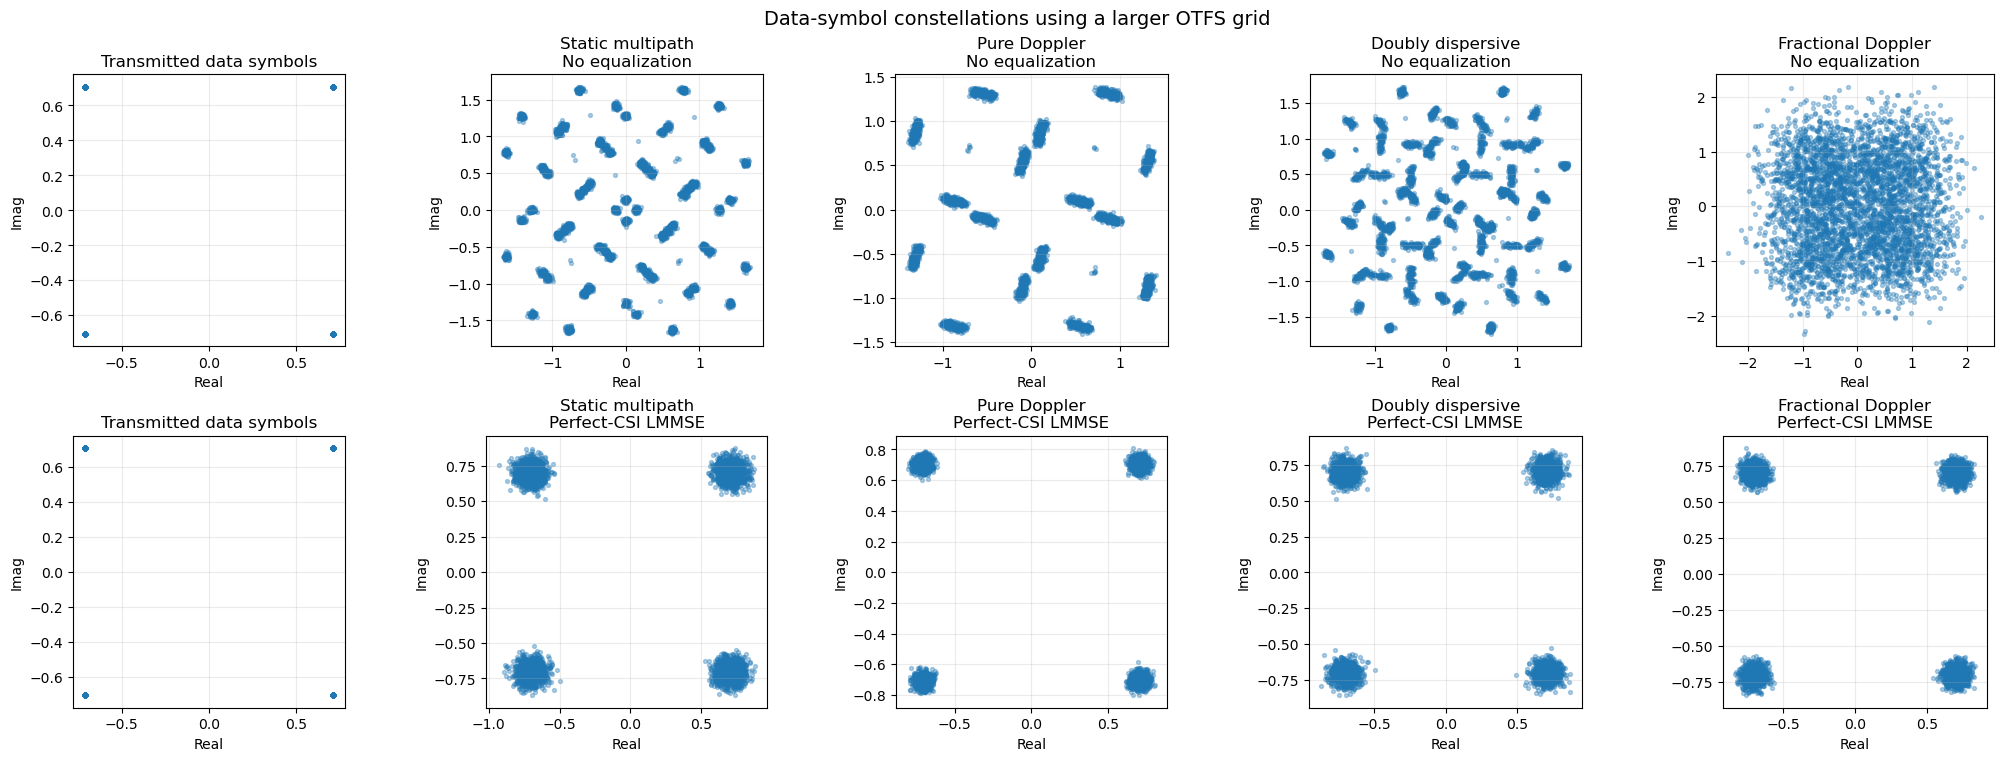

In [21]:
# ============================================================
# Larger-grid constellation experiment
# ============================================================
# The earlier sections use a small grid so that matrices and heatmaps are readable.
# For constellations, we use a larger grid only in this cell to get more data points.

# Use a larger grid only for constellation plots while keeping earlier matrix plots readable.
N_CONST = 32
M_CONST = 128
CP_LEN_CONST = CP_LEN

pilot_pattern_const = EmbeddedOTFSPilotPattern(
    num_ofdm_symbols=N_CONST,
    fft_size=M_CONST,
    subcarrier_spacing=SUBCARRIER_SPACING,
    num_tx=NUM_TX,
    num_streams_per_tx=NUM_STREAMS_PER_TX,
    lmax=LMAX_PILOT,
    kmax=KMAX_PILOT,
    pilot_symbol=PILOT_SYMBOL,
)

# Rebuild the ResourceGrid and receiver blocks because the grid dimensions changed.
rg_const = ResourceGrid(
    num_ofdm_symbols=N_CONST,
    fft_size=M_CONST,
    subcarrier_spacing=SUBCARRIER_SPACING,
    num_tx=NUM_TX,
    num_streams_per_tx=NUM_STREAMS_PER_TX,
    cyclic_prefix_length=CP_LEN_CONST,
    pilot_pattern=pilot_pattern_const,
)

rg_mapper_const = ResourceGridMapper(rg_const)
rg_demapper_const = ResourceGridDemapper(rg_const, sm)

ofdm_modulator_const = OFDMModulator(
    cyclic_prefix_length=CP_LEN_CONST,
)

ofdm_demodulator_with_cp_const = OFDMDemodulator(
    fft_size=M_CONST,
    l_min=CHANNEL_L_MIN,
    cyclic_prefix_length=CP_LEN_CONST,
)

ofdm_demodulator_no_cp_const = OFDMDemodulator(
    fft_size=M_CONST,
    l_min=CHANNEL_L_MIN,
    cyclic_prefix_length=0,
)

block_lmmse_const = BlockLMMSEEqualizer(
    num_blocks=N_CONST,
    fft_size=M_CONST,
    cyclic_prefix_length=CP_LEN_CONST,
)

channel_const = ApplyCIRTimeChannel(
    bandwidth=rg_const.bandwidth,
    l_min=CHANNEL_L_MIN,
    l_max=CHANNEL_L_MAX,
    normalize=CHANNEL_NORMALIZE,
)

awgn_const = AWGN()

num_data_bits_const = int(rg_const.num_data_symbols * NUM_BITS_PER_SYMBOL)

bits_const = binary_source(
    [
        BATCH_SIZE,
        NUM_TX,
        NUM_STREAMS_PER_TX,
        num_data_bits_const,
    ]
)

x_data_const = mapper(bits_const)

# Delay-Doppler grid with embedded pilot and guard region.
x_dd_const = rg_mapper_const(x_data_const)

# OTFS as precoded OFDM:
# DD -> TF -> CP time-domain waveform.
x_tf_const = otfs_modulator(x_dd_const)
x_time_const = ofdm_modulator_const(x_tf_const)

num_time_steps_const = get_required_num_cir_time_steps(
    num_time_samples=rg_const.num_time_samples,
    l_min=CHANNEL_L_MIN,
    l_max=CHANNEL_L_MAX,
)

no_const = ebnodb2no(
    EBNO_DB,
    NUM_BITS_PER_SYMBOL,
    CODERATE_FOR_NO,
    rg_const,
) * NUM_BITS_PER_SYMBOL

constellation_data = {}

# Use the same channel cases, but regenerate CIR tensors for the larger frame length.
for name, paths in channel_cases.items():
    generator = DDPathCIRGenerator(
        g_i=paths["g_i"],
        l_i=paths["l_i"],
        k_i=paths["k_i"],
    )

    a_const, tau_const = generator(
        batch_size=BATCH_SIZE,
        num_time_steps=num_time_steps_const,
        bandwidth=rg_const.bandwidth,
    )

    y_time_const, h_time_const = channel_const(
        x_time_const,
        a_const,
        tau_const,
    )

    y_time_noisy_const = awgn_const(
        y_time_const,
        no_const,
    )

    # ------------------------------------------------------------
    # Receiver without equalization
    # ------------------------------------------------------------
    y_tf_no_eq_const = ofdm_demodulator_with_cp_const(
        y_time_noisy_const,
    )

    y_dd_no_eq_const = otfs_demodulator(
        y_tf_no_eq_const,
    )

    x_hat_no_eq_const = rg_demapper_const(
        y_dd_no_eq_const,
    )

    # ------------------------------------------------------------
    # Perfect-CSI block LMMSE receiver
    # ------------------------------------------------------------
    # Perfect-CSI LMMSE on the larger constellation grid.
    gs_true_const = h_time_to_gs(
        h_time_const,
        rg_const.num_time_samples,
    )

    y_time_lmmse_const = block_lmmse_const(
        y_time_noisy_const,
        gs_true_const,
        no_const,
    )

    y_tf_lmmse_const = ofdm_demodulator_no_cp_const(
        y_time_lmmse_const,
    )

    y_dd_lmmse_const = otfs_demodulator(
        y_tf_lmmse_const,
    )

    x_hat_lmmse_const = rg_demapper_const(
        y_dd_lmmse_const,
    )

    # Store demapped data symbols before and after LMMSE for comparison.
    constellation_data[name] = {
        "x_hat_no_eq": x_hat_no_eq_const,
        "x_hat_lmmse": x_hat_lmmse_const,
    }

    print("=" * 70)
    print(name)
    print("x_dd_const shape:          ", x_dd_const.shape)
    print("x_time_const shape:        ", x_time_const.shape)
    print("x_hat_no_eq_const shape:   ", x_hat_no_eq_const.shape)
    print("x_hat_lmmse_const shape:   ", x_hat_lmmse_const.shape)


# ============================================================
# Plot constellations
# ============================================================

x_symbols_const = x_data_const.numpy()[0, 0, 0].reshape(-1)

fig, axes = plt.subplots(
    2,
    len(constellation_data) + 1,
    figsize=(4.1 * (len(constellation_data) + 1), 7.5),
    constrained_layout=True,
)

# Reference transmitted symbols.
for row in range(2):
    axes[row, 0].scatter(
        np.real(x_symbols_const),
        np.imag(x_symbols_const),
        s=8,
        alpha=0.45,
    )
    axes[row, 0].set_title("Transmitted data symbols")
    axes[row, 0].set_xlabel("Real")
    axes[row, 0].set_ylabel("Imag")
    axes[row, 0].grid(True, alpha=0.25)
    axes[row, 0].set_aspect("equal", adjustable="box")

for col, (name, data) in enumerate(constellation_data.items(), start=1):
    y_no_eq = data["x_hat_no_eq"].numpy()[0, 0, 0].reshape(-1)
    y_lmmse = data["x_hat_lmmse"].numpy()[0, 0, 0].reshape(-1)

    axes[0, col].scatter(
        np.real(y_no_eq),
        np.imag(y_no_eq),
        s=8,
        alpha=0.35,
    )
    axes[0, col].set_title(f"{name}\nNo equalization")
    axes[0, col].set_xlabel("Real")
    axes[0, col].set_ylabel("Imag")
    axes[0, col].grid(True, alpha=0.25)
    axes[0, col].set_aspect("equal", adjustable="box")

    axes[1, col].scatter(
        np.real(y_lmmse),
        np.imag(y_lmmse),
        s=8,
        alpha=0.35,
    )
    axes[1, col].set_title(f"{name}\nPerfect-CSI LMMSE")
    axes[1, col].set_xlabel("Real")
    axes[1, col].set_ylabel("Imag")
    axes[1, col].grid(True, alpha=0.25)
    axes[1, col].set_aspect("equal", adjustable="box")

fig.suptitle(
    "Data-symbol constellations using a larger OTFS grid",
    fontsize=14,
)

plt.show()

## 14. Summary

This notebook established the complete OTFS signal chain as a working Sionna-compatible system, using the implementation blocks directly without any simulation-model wrapper.

The key implementation points are:

- **OTFS as precoded OFDM.** `OTFSModulator` applies the ISFFT between `ResourceGridMapper` and `OFDMModulator`; `OTFSDemodulator` applies the SFFT between `OFDMDemodulator` and `ResourceGridDemapper`. The standard Sionna OFDM infrastructure is unchanged.
- **Uniform spreading.** The ISFFT distributes each delay-Doppler symbol uniformly across the full time-frequency grid, confirmed by the approximately constant magnitude of `X_tf` after precoding.
- **Pilot isolation.** The embedded guard region correctly isolates the pilot response from data symbols across all four channel cases.
- **Perfect-CSI reference.** Block LMMSE equalization with `gs_true` recovers the delay-Doppler symbols successfully, confirming that the implementation chain is end-to-end consistent.
- **Fractional Doppler residual.** The integer-tap channel model introduces residual error for off-grid Doppler paths even with perfect CSI, setting a floor that motivates the threshold sensitivity analysis in Notebook 4.

Notebook 4 extends this pipeline by adding the embedded-pilot channel estimation step, connecting the received pilot response to the `gs_est` channel estimate used by the equalizer.